<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/5d_ac_quitaruido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autocodificadores quita ruido
En esta libreta programaremos autocodificadores quita ruido con redes densas y los aplicaremos al conjunto de imágenes de ropa Fashion-MNIST.

Un autocodificador quita ruido recibe una versión corrupta $\tilde{\mathbf{x}}$ de una imagen y se entrena para reconstruir la imagen original $\mathbf{x}$. Compararemos dos variantes:

1. Un autocodificador subcompleto, cuya capa oculta tiene menos unidades que la entrada.
2. Un autocodificador sobrecompleto con un regularizador que promueve activaciones dispersas.

In [1]:
import os

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import numpy as np

import torch as th
from torch import nn
from torch.nn import Sequential, Linear, Sigmoid
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import FashionMNIST

from torch.utils.tensorboard import SummaryWriter

N_EPOCAS = 30
T_LOTE = 64
MEDIA_RUIDO = 0.1
STD_RUIDO = 0.2
D_LATENTE_SUB = 100
D_LATENTE_DISP = 1200
LAMBDA_DISP = 0.01
SEED = 42
LR = 1e-3
TBDIR = 'runs/'
DC = th.device('cuda' if th.cuda.is_available() else 'cpu')

# Para reproducibilidad
np.random.seed(SEED)
th.manual_seed(SEED)

## Conjunto de datos
Descargamos los subconjuntos de entrenamiento y prueba de Fashion-MNIST:

In [2]:
ent = FashionMNIST(root = 'fashion_mnist',
                   train = True,
                   download = True)

prueba = FashionMNIST(root = 'fashion_mnist',
                      train = False,
                      download = True)

100%|██████████| 26.4M/26.4M [00:03<00:00, 7.96MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.59MB/s]


Como los autocodificadores que vamos a programar tienen únicamente capas densas, aplanamos cada imagen de $28 \times 28$ en un vector de 784 elementos. Además, escalamos los valores de los píxeles de $[0, 255]$ a $[0, 1]$.

In [3]:
H, W = ent.data.shape[1:]
D_ENTRADA = H * W

# Aplanamos imágenes en vectores
X_ent = ent.data.reshape(ent.data.shape[0], D_ENTRADA).float()
X_prueba = prueba.data.reshape(prueba.data.shape[0], D_ENTRADA).float()

# Escalamos valores a intervalo [0, 1]
X_ent = X_ent / 255
X_prueba = X_prueba / 255

X_ent.shape, X_prueba.shape

(torch.Size([60000, 784]), torch.Size([10000, 784]))

Definimos una función que corrompe las imágenes sumándoles ruido gaussiano con media `MEDIA_RUIDO` y desviación estándar `STD_RUIDO`. Recortamos el resultado al intervalo $[0, 1]$ para que las imágenes ruidosas tengan el mismo rango que las originales.

In [4]:
def agrega_ruido(X: th.Tensor,
                 media: float = MEDIA_RUIDO,
                 std: float = STD_RUIDO) -> th.Tensor:
  ruido = th.randn(X.shape) * std + media
  return (X + ruido).clamp(0, 1)

Definimos una subclase de `Dataset` que regresa una versión ruidosa de cada imagen junto con la imagen original. El ruido se genera cada vez que se accede a una imagen, de modo que en cada época el modelo ve una corrupción distinta de la misma imagen.

In [5]:
class MiDS(Dataset):
  def __init__(self,
               X: th.Tensor) -> None:
    self.x = X

  def __getitem__(self,
                  i: int) -> tuple[th.Tensor, th.Tensor]:
    return agrega_ruido(self.x[i]), self.x[i]

  def __len__(self) -> int:
    return len(self.x)

Definimos una función para desplegar imágenes en una cuadrícula. Como los valores están en $[0, 1]$, fijamos `vmin` y `vmax` para que `imshow` no reescale cada imagen por separado.

In [6]:
def visualiza_imagenes(xs: np.ndarray,
                       n_filas: int = 10,
                       n_columnas: int = 10,
                       t_celda: float = 1.0,
                       alto: int = 28,
                       ancho: int = 28,
                       titulos_filas: list[str] | None = None) -> None:
  fig, axs = plt.subplots(nrows = n_filas,
                          ncols = n_columnas,
                          figsize = (t_celda * n_columnas, t_celda * n_filas),
                          squeeze = False,
                          gridspec_kw = {'wspace': 0.05, 'hspace': 0.05})

  for idx, ax in enumerate(axs.flat):
    ax.set_xticks([])
    ax.set_yticks([])
    if idx < len(xs):
      ax.imshow(xs[idx].reshape(alto, ancho),
                cmap = 'gray',
                vmin = 0,
                vmax = 1)

  if titulos_filas is not None:
    for ax, titulo in zip(axs[:, 0], titulos_filas):
      ax.set_ylabel(titulo, fontsize = 9)

  plt.show()

Creamos el cargador de datos para el subconjunto de entrenamiento y visualizamos algunas imágenes ruidosas (primera fila) con sus originales (segunda fila).

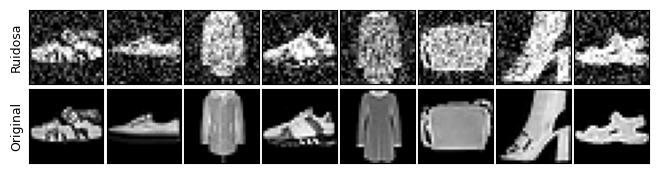

In [7]:
entds = MiDS(X_ent)
entdl = DataLoader(entds,
                   batch_size = T_LOTE,
                   shuffle = True,
                   drop_last = True)

Xr, Xo = next(iter(entdl))
visualiza_imagenes(th.cat([Xr[:8], Xo[:8]]).numpy(),
                   n_filas = 2,
                   n_columnas = 8,
                   alto = H,
                   ancho = W,
                   titulos_filas = ['Ruidosa', 'Original'])

Para el subconjunto de prueba generamos una sola versión ruidosa de las imágenes.

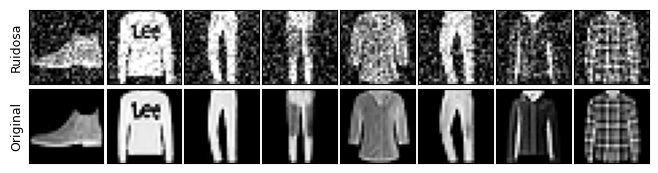

In [8]:
X_prueba_ruidosa = agrega_ruido(X_prueba)

visualiza_imagenes(th.cat([X_prueba_ruidosa[:8], X_prueba[:8]]).numpy(),
                   n_filas = 2,
                   n_columnas = 8,
                   alto = H,
                   ancho = W,
                   titulos_filas = ['Ruidosa', 'Original'])

## Autocodificador
Definimos un autocodificador con una sola capa oculta tanto en el codificador como en el decodificador, ambas con función de activación sigmoide. Como las imágenes están en $[0, 1]$, la sigmoide de la salida produce reconstrucciones en el mismo rango. El método `forward` regresa la reconstrucción y las activaciones $\mathbf{z}$ de la capa oculta, que necesitaremos para el regularizador de dispersión.

In [9]:
class Autocodificador(nn.Module):
  def __init__(self,
               d_ent: int,
               d_ocultas: int) -> None:
    super().__init__()

    self.cod = Sequential(Linear(d_ent, d_ocultas),
                          Sigmoid())

    self.dec = Sequential(Linear(d_ocultas, d_ent),
                          Sigmoid())

  def forward(self,
              x: th.Tensor) -> tuple[th.Tensor, th.Tensor]:
    z = self.cod(x)
    xrec = self.dec(z)

    return xrec, z

## Función de pérdida
La función de pérdida es el error cuadrático entre la reconstrucción $\hat{\mathbf{x}}$ de la imagen ruidosa $\tilde{\mathbf{x}}$ y la imagen original $\mathbf{x}$, más una penalización por norma $\ell_1$ sobre el vector latente $\mathbf{z}$ (las activaciones de la capa oculta) ponderada por $\lambda$:

$$
\mathcal{L}(\boldsymbol{\theta}) = \frac{1}{N} \sum_{i=1}^{N} \left[\Vert \mathbf{x}^{(i)} - \hat{\mathbf{x}}^{(i)} \Vert_2^2 + \lambda \Vert \mathbf{z}^{(i)} \Vert_1\right]
$$

donde $\hat{\mathbf{x}}^{(i)}$ y $\mathbf{z}^{(i)}$ son la reconstrucción y el vector latente que produce el autocodificador para $\tilde{\mathbf{x}}^{(i)}$ y $N$ es el tamaño del lote. Con $\lambda = 0$ tenemos un autocodificador quita ruido sin penalización.

In [10]:
class PerdidaAC(nn.Module):
  def __init__(self,
               lambda_disp: float = 0.0) -> None:
    super().__init__()

    self.lambda_disp = lambda_disp
    self.mse = nn.MSELoss(reduction = 'sum')

  def forward(self,
              xrec: th.Tensor,
              x: th.Tensor,
              z: th.Tensor) -> th.Tensor:
    n = x.shape[0]
    ec = self.mse(xrec, x) / n
    disp = z.abs().sum() / n
    return ec + self.lambda_disp * disp

## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Registrar información para TensorBoard
Para guardar información que pueda visualizarse con TensorBoard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ejemplo, `add_scalar`, `add_image`, `add_histogram`, etc.).

In [11]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, np.ndarray]) -> None:
  for (m, v) in hist.items():
    writer.add_scalar(m, v[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida como instancia de `PerdidaAC` (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* Una instancia de `Tensor` con el lote de imágenes ruidosas (`Xr`).
* Una instancia de `Tensor` con el lote de imágenes originales (`Xo`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

En cada paso de entrenamiento, el lote de imágenes ruidosas se pasa por el autocodificador para obtener las reconstrucciones y las activaciones de la capa oculta, se calcula la pérdida con respecto a las imágenes originales, se obtienen los gradientes y se actualizan los parámetros. Si el dispositivo es una GPU que soporta `bfloat16` de forma nativa, usamos precisión mixta.

In [12]:
def paso_ent(modelo: nn.Module,
             fp: PerdidaAC,
             opt: th.optim.Optimizer,
             Xr: th.Tensor,
             Xo: th.Tensor,
             disp: str | th.device) -> th.Tensor:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()
  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  with th.autocast(device_type = tipo_disp,
                   dtype = th.bfloat16, enabled = usa_amp):
    # Propagamos las imágenes ruidosas para obtener las reconstrucciones
    Xrec, Z = modelo(Xr)

    # Calculamos la pérdida con respecto a las imágenes originales
    perdida = fp(Xrec, Xo, Z)

  # Obtenemos los gradientes
  perdida.backward()

  # Actualizamos todos los parámetros del modelo
  opt.step()

  return perdida.detach()

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos del subconjunto de entrenamiento (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

In [13]:
def entrena_epoca(modelo: nn.Module,
                  fp: PerdidaAC,
                  opt: th.optim.Optimizer,
                  dl: DataLoader,
                  disp: th.device | str = 'cuda') -> float:
  n_total = 0
  suma_perdida = 0.0

  modelo.train()
  for Xr, Xo in dl:
    Xr = Xr.to(disp)
    Xo = Xo.to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            opt,
                            Xr,
                            Xo,
                            disp)

    n_lote = Xr.shape[0]
    n_total += n_lote

    # La pérdida es el promedio sobre las imágenes del lote
    suma_perdida += perdida_paso * n_lote

  perdida_epoca = (suma_perdida / n_total).item()
  return perdida_epoca

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).
* El número de épocas de entrenamiento (`n_epocas`).
* La ruta al directorio donde se guardará la información para TensorBoard (`tbdir`).

In [14]:
def entrena(modelo: nn.Module,
            fp: PerdidaAC,
            opt: th.optim.Optimizer,
            dl: DataLoader,
            disp: th.device | str = 'cuda',
            n_epocas: int = 30,
            tbdir: str = 'runs/') -> tuple[nn.Module, dict[str, np.ndarray]]:

  hist = {
    'perdida': np.zeros(n_epocas)
    }

  tbwriter = SummaryWriter(tbdir)

  modelo.to(disp)
  for e in tqdm(range(n_epocas)):
    hist['perdida'][e] = entrena_epoca(modelo,
                                       fp,
                                       opt,
                                       dl,
                                       disp)

    registra_info_tboard(tbwriter, e, hist)

    print(f'Época {e}: '
          f'Pérdida = {hist["perdida"][e]:.3f}')

  tbwriter.close()

  return modelo, hist

## Funciones para la evaluación
Definimos una función que pasa el modelo a la CPU, lo pone en modo de evaluación y obtiene las reconstrucciones y las activaciones de la capa oculta para un conjunto de imágenes ruidosas.

In [15]:
@th.inference_mode()
def evalua(modelo: nn.Module,
           Xr: th.Tensor) -> tuple[th.Tensor, th.Tensor]:
  modelo = modelo.to('cpu')
  modelo.eval()
  return modelo(Xr)

También definimos una función para visualizar algunas imágenes ruidosas de prueba (primera fila), sus reconstrucciones (segunda fila) y las imágenes originales (tercera fila).

In [16]:
def visualiza_reconstrucciones(Xr: th.Tensor,
                               Xrec: th.Tensor,
                               Xo: th.Tensor,
                               n: int = 8) -> None:
  visualiza_imagenes(th.cat([Xr[:n], Xrec[:n], Xo[:n]]).numpy(),
                     n_filas = 3,
                     n_columnas = n,
                     alto = H,
                     ancho = W,
                     titulos_filas = ['Ruidosa', 'Reconstruida', 'Original'])

## Autocodificador subcompleto
Instanciamos un autocodificador y lo entrenamos sin regularizador de dispersión.

In [17]:
ac = Autocodificador(D_ENTRADA, D_LATENTE_SUB)

fp = PerdidaAC(lambda_disp = 0.0)

opt = Adam(ac.parameters(), lr = LR)

ac, hist = entrena(ac,
                   fp,
                   opt,
                   entdl,
                   disp = DC,
                   n_epocas = N_EPOCAS,
                   tbdir = os.path.join(TBDIR, 'subcompleto'))

  0%|          | 0/30 [00:00<?, ?it/s]

Época 0: Pérdida = 32.408
Época 1: Pérdida = 17.310
Época 2: Pérdida = 13.718
Época 3: Pérdida = 11.863
Época 4: Pérdida = 10.811
Época 5: Pérdida = 10.112
Época 6: Pérdida = 9.614
Época 7: Pérdida = 9.246
Época 8: Pérdida = 8.954
Época 9: Pérdida = 8.735
Época 10: Pérdida = 8.555
Época 11: Pérdida = 8.405
Época 12: Pérdida = 8.297
Época 13: Pérdida = 8.195
Época 14: Pérdida = 8.111
Época 15: Pérdida = 8.050
Época 16: Pérdida = 7.988
Época 17: Pérdida = 7.945
Época 18: Pérdida = 7.897
Época 19: Pérdida = 7.872
Época 20: Pérdida = 7.834
Época 21: Pérdida = 7.808
Época 22: Pérdida = 7.787
Época 23: Pérdida = 7.762
Época 24: Pérdida = 7.748
Época 25: Pérdida = 7.732
Época 26: Pérdida = 7.718
Época 27: Pérdida = 7.706
Época 28: Pérdida = 7.683
Época 29: Pérdida = 7.685


Graficamos la pérdida por época.

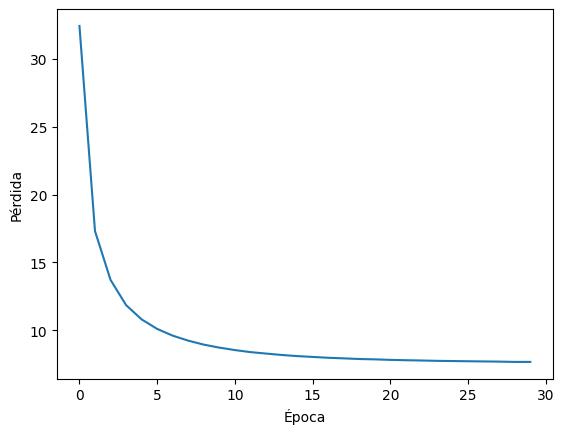

In [18]:
plt.plot(hist['perdida'])
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.show()

Visualizamos los resultados con algunas imágenes de prueba.

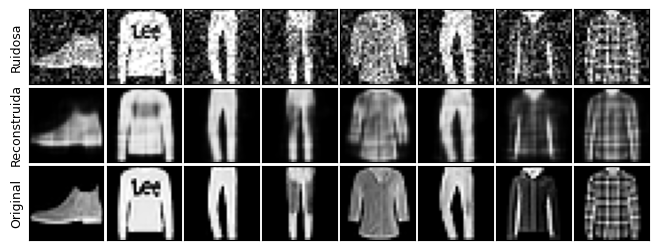

In [19]:
Xrec, Z = evalua(ac, X_prueba_ruidosa)
visualiza_reconstrucciones(X_prueba_ruidosa, Xrec, X_prueba)

## Autocodificador disperso
Instanciamos un autocodificador sobrecompleto y lo entrenamos con el regularizador de dispersión.

In [20]:
acdis = Autocodificador(D_ENTRADA, D_LATENTE_DISP)

fp = PerdidaAC(lambda_disp = LAMBDA_DISP)

opt = Adam(acdis.parameters(), lr = LR)

acdis, hist = entrena(acdis,
                      fp,
                      opt,
                      entdl,
                      disp = DC,
                      n_epocas = N_EPOCAS,
                      tbdir = os.path.join(TBDIR, 'disperso'))

  0%|          | 0/30 [00:00<?, ?it/s]

Época 0: Pérdida = 20.374
Época 1: Pérdida = 11.349
Época 2: Pérdida = 9.410
Época 3: Pérdida = 8.377
Época 4: Pérdida = 7.712
Época 5: Pérdida = 7.246
Época 6: Pérdida = 6.896
Época 7: Pérdida = 6.646
Época 8: Pérdida = 6.418
Época 9: Pérdida = 6.261
Época 10: Pérdida = 6.112
Época 11: Pérdida = 6.001
Época 12: Pérdida = 5.904
Época 13: Pérdida = 5.821
Época 14: Pérdida = 5.750
Época 15: Pérdida = 5.674
Época 16: Pérdida = 5.614
Época 17: Pérdida = 5.567
Época 18: Pérdida = 5.519
Época 19: Pérdida = 5.479
Época 20: Pérdida = 5.437
Época 21: Pérdida = 5.407
Época 22: Pérdida = 5.365
Época 23: Pérdida = 5.340
Época 24: Pérdida = 5.311
Época 25: Pérdida = 5.278
Época 26: Pérdida = 5.253
Época 27: Pérdida = 5.229
Época 28: Pérdida = 5.215
Época 29: Pérdida = 5.187


Graficamos la pérdida por época. Esta pérdida incluye el regularizador, por lo que no es directamente comparable con la del autocodificador subcompleto.

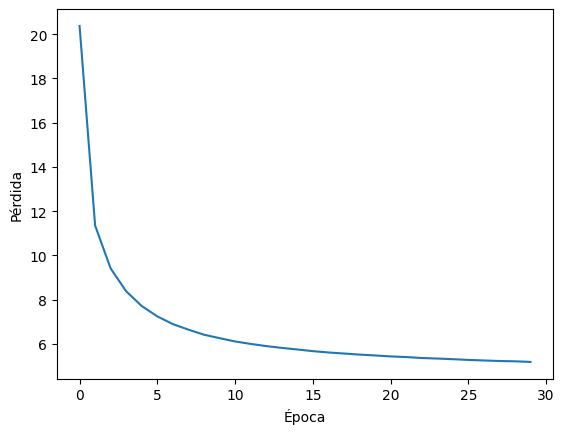

In [21]:
plt.plot(hist['perdida'])
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.show()

Visualizamos los resultados con algunas imágenes de prueba.

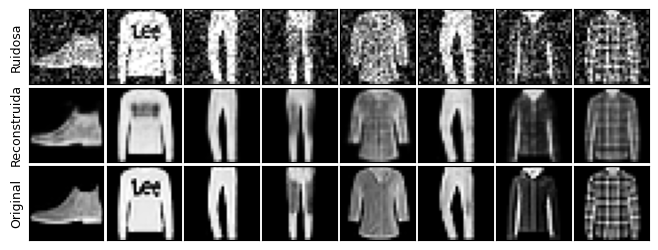

In [22]:
Xrec_dis, Z_dis = evalua(acdis, X_prueba_ruidosa)
visualiza_reconstrucciones(X_prueba_ruidosa, Xrec_dis, X_prueba)

## Comparación
Comparamos el error cuadrático medio por píxel de las reconstrucciones de ambos autocodificadores en el subconjunto de prueba.

In [23]:
ecm = ((Xrec - X_prueba)**2).mean().item()
ecm_dis = ((Xrec_dis - X_prueba)**2).mean().item()
print(f'ECM subcompleto: {ecm:.4f}')
print(f'ECM disperso: {ecm_dis:.4f}')

ECM subcompleto: 0.0099
ECM disperso: 0.0064


Comparamos también las distribuciones de las activaciones de la capa oculta de ambos autocodificadores en el subconjunto de prueba.

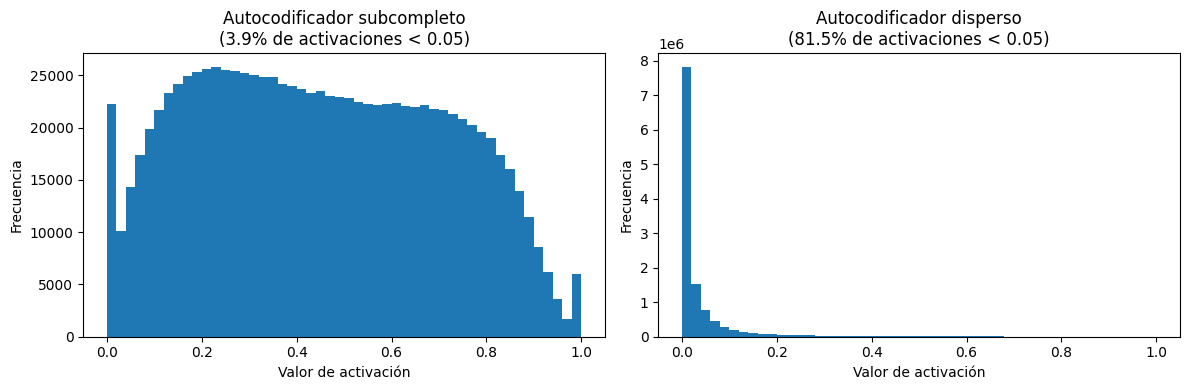

In [24]:
fig, axs = plt.subplots(1, 2, figsize = (12, 4))
for ax, Zs, titulo in zip(axs,
                          [Z, Z_dis],
                          ['Autocodificador subcompleto', 'Autocodificador disperso']):
  frac = (Zs < 0.05).float().mean().item()
  ax.hist(Zs.numpy().flatten(), bins = 50)
  ax.set_xlabel('Valor de activación')
  ax.set_ylabel('Frecuencia')
  ax.set_title(f'{titulo}\n({100 * frac:.1f}% de activaciones < 0.05)')
plt.tight_layout()
plt.show()